Mounted at /content/drive
os valores dos picos são: []


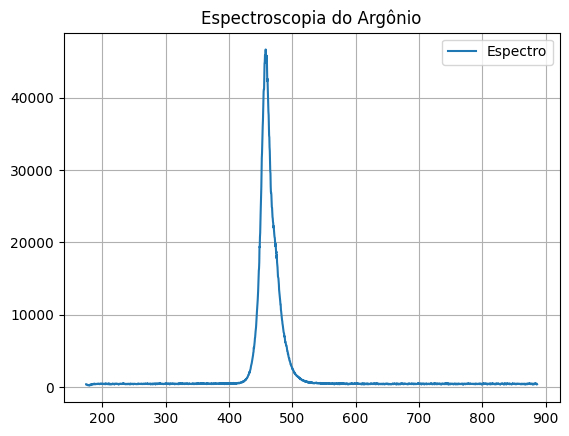

In [4]:
from numpy import loadtxt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks, peak_widths
from google.colab import drive
from random import randint
from matplotlib.pyplot import plot, grid, title, legend, show, annotate
drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/F740/Cópia de LED_AZUL_458,32_2.txt'

# Função para limpar cada valor, removendo BOM e substituindo vírgula por ponto
def clean_number(x):
    return float(x.strip().replace('\ufeff', '').replace(',', '.'))

# Ler arquivo com duas colunas separadas por espaços (ou múltiplos espaços)
data = np.loadtxt(file_path,
                  converters={0: clean_number, 1: clean_number})

# Separar colunas
x = data[:, 0]
y = data[:, 1]

# Detectar picos acima de 2000
picos, _ = find_peaks(y, height=2000)

# Detectar picos acima de 2000
picos, _ = find_peaks(y, height=2000)
#Filtro
x_limite = 1400.0
picos = [pico for pico in picos if x[pico] > x_limite]
peak_value = x[picos]

print(f'os valores dos picos são: {peak_value}')

plot(x, y, label="Espectro")
cores_aleatorias = [f'#{randint(0, 0xFFFFFF):06x}' for _ in picos]

for i, pico in enumerate(picos):
    # Alterna entre esquerda e direita
    x_offset = 30 if i % 2 == 0 else -30
    y_offset = 0
    colour = cores_aleatorias[i]

    plot(x[pico], y[pico], '*', markersize=15, color=colour, markeredgecolor='black')
    # annotate(f'{x[pico]:.2f}',
    #             xy=(x[pico], y[pico]),
    #             xytext=(x_offset, y_offset),
    #             textcoords='offset points',
    #             ha='center',
    #             arrowprops=dict(arrowstyle='->', color=colour, lw=1, alpha=0.7),
    #             bbox=dict(boxstyle='round,pad=0.3', facecolor=colour, alpha=0.8),
    #             fontsize=9)
grid()
title("Espectroscopia do Argônio")
legend()
show()

widths, h_eval, left_ips, right_ips = peak_widths(y, picos)

for i, p in enumerate(picos):
    xc = x[p]
    fwhm = widths[i] * (x[1]-x[0])
    err_xc = fwhm /(2*6**(1/2))

    print(f"Pico em x = {xc:.2f} ± {err_xc:.2f} (FWHM = {fwhm:.2f})")

#[1444, 1475, 1500, 1538, 1573, 1613, 1651,1678, 1716, 1749, 1771, 1845,
#1851, 1857, 1903, 1935, 1945, 1994]

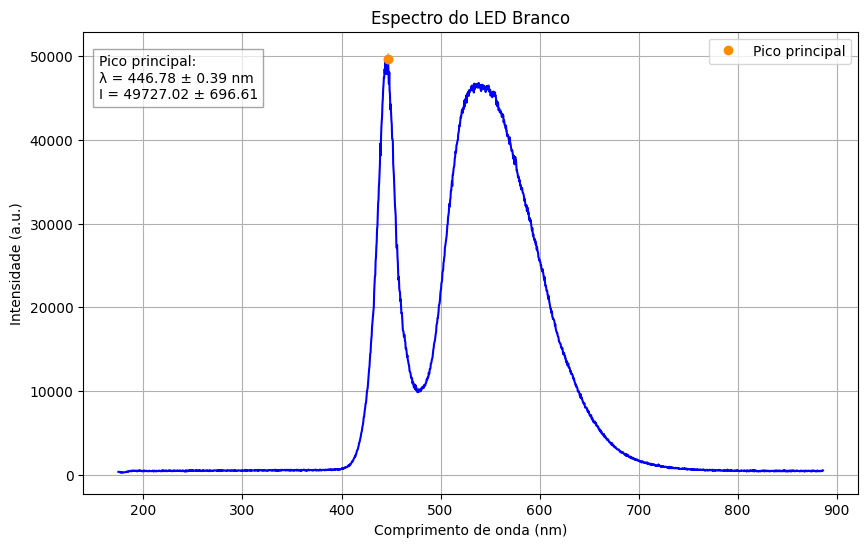

Pico principal: λ = 446.78 ± 0.39 nm, I = 49727.02 ± 696.61


In [16]:
import numpy as np
import matplotlib.pyplot as plt

# Caminho do arquivo
file_path = '/content/drive/MyDrive/F740/LED_BRANCO_454,99.txt'

# Função para limpar números (remover BOM e substituir vírgula por ponto)
def clean_number(x):
    return float(x.strip().replace('\ufeff', '').replace(',', '.'))

# Ler os dados
data = np.loadtxt(file_path, converters={0: clean_number, 1: clean_number})
wavelength = data[:,0]  # nm
intensity = data[:,1]

# Encontrar o pico principal
idx_max = np.argmax(intensity)
lambda_peak = wavelength[idx_max]
intensity_peak = intensity[idx_max]

# Estimar incertezas
sigma_lambda = wavelength[1] - wavelength[0]  # ±1 pixel
sigma_intensity = np.std(intensity[max(0, idx_max-2):idx_max+3])  # ±2 pontos vizinhos

# Plotar espectro com o pico destacado
plt.figure(figsize=(10,6))
# Curva do espectro
line_curve, = plt.plot(wavelength, intensity, label='Espectro', color='blue')
# Pico principal
line_peak, = plt.plot(lambda_peak, intensity_peak, 'o', color='darkorange', label='Pico principal')
# Barra de erro
err_peak = plt.errorbar(lambda_peak, intensity_peak,
                        xerr=sigma_lambda, yerr=sigma_intensity,
                        fmt='o', color='darkorange', alpha=0.5)

# Legenda da curva no canto superior esquerdo
plt.legend(handles=[line_curve], loc='upper left')

# Legenda do pico no canto inferior direito
plt.legend(handles=[line_peak], loc='upper right')

# Texto do pico no canto superior esquerdo
plt.text(0.02, 0.95,  # coordenadas relativas (x, y) no eixo [0,1]
         f'Pico principal:\nλ = {lambda_peak:.2f} ± {sigma_lambda:.2f} nm\n'
         f'I = {intensity_peak:.2f} ± {sigma_intensity:.2f}',
         transform=plt.gca().transAxes, fontsize=10, verticalalignment='top',
         color='black', bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray'))

plt.xlabel('Comprimento de onda (nm)')
plt.ylabel('Intensidade (a.u.)')
plt.title('Espectro do LED Branco')
plt.grid(True)
plt.show()

print(f"Pico principal: λ = {lambda_peak:.2f} ± {sigma_lambda:.2f} nm, "
      f"I = {intensity_peak:.2f} ± {sigma_intensity:.2f}")


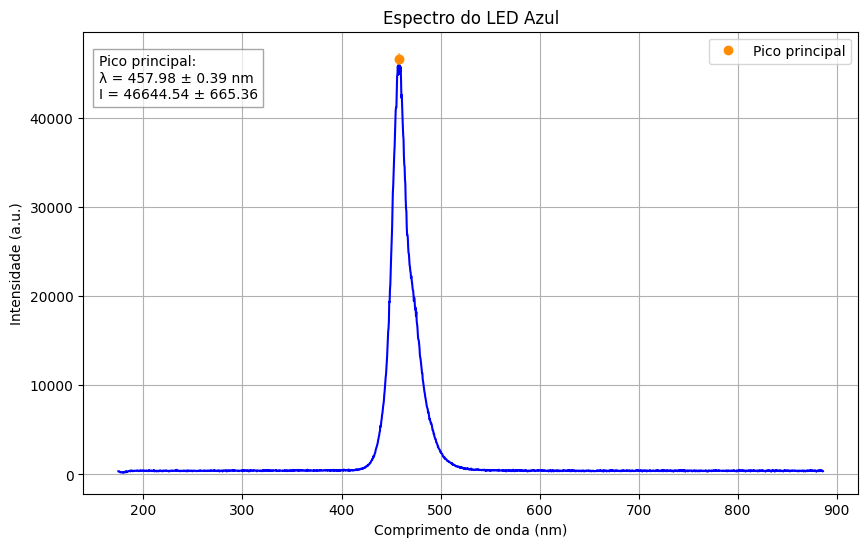

Pico principal: λ = 457.98 ± 0.39 nm, I = 46644.54 ± 665.36


In [27]:
import numpy as np
import matplotlib.pyplot as plt

# Caminho do arquivo
file_path = '/content/drive/MyDrive/F740/Cópia de LED_AZUL_458,32_2.txt'

# Função para limpar números (remover BOM e substituir vírgula por ponto)
def clean_number(x):
    return float(x.strip().replace('\ufeff', '').replace(',', '.'))

# Ler os dados
data = np.loadtxt(file_path, converters={0: clean_number, 1: clean_number})
wavelength = data[:,0]  # nm
intensity = data[:,1]

# Encontrar o pico principal
idx_max = np.argmax(intensity)
lambda_peak = wavelength[idx_max]
intensity_peak = intensity[idx_max]

# Estimar incertezas
sigma_lambda = wavelength[1] - wavelength[0]  # ±1 pixel
sigma_intensity = np.std(intensity[max(0, idx_max-2):idx_max+3])  # ±2 pontos vizinhos

# Plotar espectro com o pico destacado
plt.figure(figsize=(10,6))
# Curva do espectro
line_curve, = plt.plot(wavelength, intensity, label='Espectro', color='blue')
# Pico principal
line_peak, = plt.plot(lambda_peak, intensity_peak, 'o', color='darkorange', label='Pico principal')
# Barra de erro
err_peak = plt.errorbar(lambda_peak, intensity_peak,
                        xerr=sigma_lambda, yerr=sigma_intensity,
                        fmt='o', color='darkorange', alpha=0.5)

# Legenda da curva no canto superior esquerdo
plt.legend(handles=[line_curve], loc='upper left')

# Legenda do pico no canto inferior direito
plt.legend(handles=[line_peak], loc='upper right')

# Texto do pico no canto superior esquerdo
plt.text(0.02, 0.95,  # coordenadas relativas (x, y) no eixo [0,1]
         f'Pico principal:\nλ = {lambda_peak:.2f} ± {sigma_lambda:.2f} nm\n'
         f'I = {intensity_peak:.2f} ± {sigma_intensity:.2f}',
         transform=plt.gca().transAxes, fontsize=10, verticalalignment='top',
         color='black', bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray'))

plt.xlabel('Comprimento de onda (nm)')
plt.ylabel('Intensidade (a.u.)')
plt.title('Espectro do LED Azul')
plt.grid(True)
plt.show()

print(f"Pico principal: λ = {lambda_peak:.2f} ± {sigma_lambda:.2f} nm, "
      f"I = {intensity_peak:.2f} ± {sigma_intensity:.2f}")


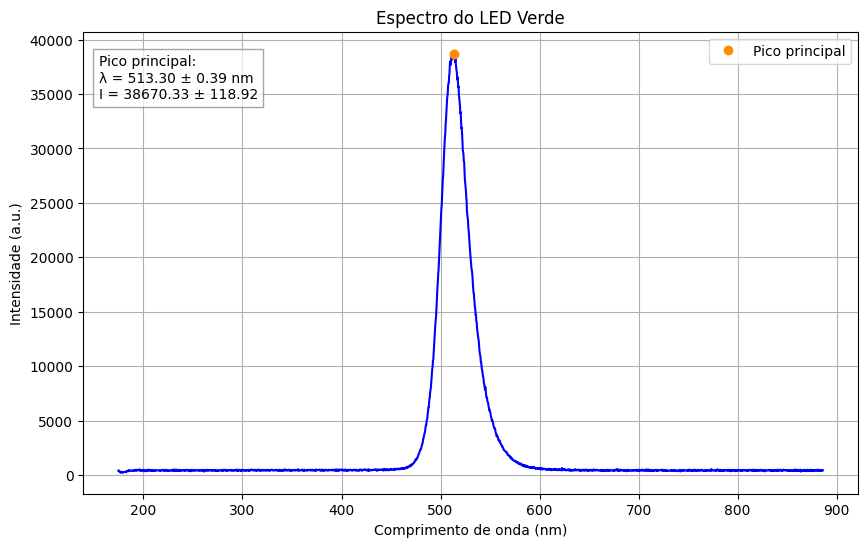

Pico principal: λ = 513.30 ± 0.39 nm, I = 38670.33 ± 118.92


In [26]:
import numpy as np
import matplotlib.pyplot as plt

# Caminho do arquivo
file_path = '/content/drive/MyDrive/F740/LED_VERDE1_513,79.txt'

# Função para limpar números (remover BOM e substituir vírgula por ponto)
def clean_number(x):
    return float(x.strip().replace('\ufeff', '').replace(',', '.'))

# Ler os dados
data = np.loadtxt(file_path, converters={0: clean_number, 1: clean_number})
wavelength = data[:,0]  # nm
intensity = data[:,1]

# Encontrar o pico principal
idx_max = np.argmax(intensity)
lambda_peak = wavelength[idx_max]
intensity_peak = intensity[idx_max]

# Estimar incertezas
sigma_lambda = wavelength[1] - wavelength[0]  # ±1 pixel
sigma_intensity = np.std(intensity[max(0, idx_max-2):idx_max+3])  # ±2 pontos vizinhos

# Plotar espectro com o pico destacado
plt.figure(figsize=(10,6))
# Curva do espectro
line_curve, = plt.plot(wavelength, intensity, label='Espectro', color='blue')
# Pico principal
line_peak, = plt.plot(lambda_peak, intensity_peak, 'o', color='darkorange', label='Pico principal')
# Barra de erro
err_peak = plt.errorbar(lambda_peak, intensity_peak,
                        xerr=sigma_lambda, yerr=sigma_intensity,
                        fmt='o', color='darkorange', alpha=0.5)

# Legenda da curva no canto superior esquerdo
plt.legend(handles=[line_curve], loc='upper left')

# Legenda do pico no canto inferior direito
plt.legend(handles=[line_peak], loc='upper right')

# Texto do pico no canto superior esquerdo
plt.text(0.02, 0.95,  # coordenadas relativas (x, y) no eixo [0,1]
         f'Pico principal:\nλ = {lambda_peak:.2f} ± {sigma_lambda:.2f} nm\n'
         f'I = {intensity_peak:.2f} ± {sigma_intensity:.2f}',
         transform=plt.gca().transAxes, fontsize=10, verticalalignment='top',
         color='black', bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray'))

plt.xlabel('Comprimento de onda (nm)')
plt.ylabel('Intensidade (a.u.)')
plt.title('Espectro do LED Verde')
plt.grid(True)
plt.show()

print(f"Pico principal: λ = {lambda_peak:.2f} ± {sigma_lambda:.2f} nm, "
      f"I = {intensity_peak:.2f} ± {sigma_intensity:.2f}")


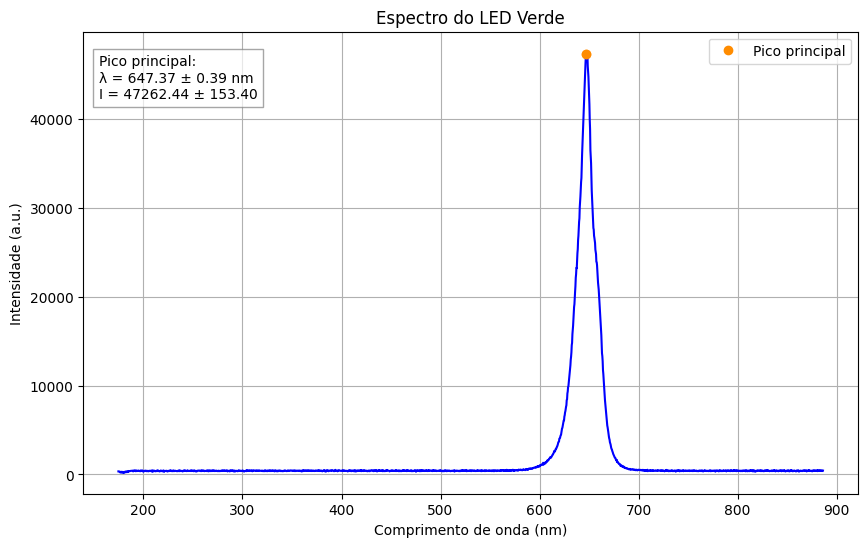

Pico principal: λ = 647.37 ± 0.39 nm, I = 47262.44 ± 153.40


In [25]:
import numpy as np
import matplotlib.pyplot as plt

# Caminho do arquivo
file_path = '/content/drive/MyDrive/F740/LED_VERMELHO_648,78.txt'

# Função para limpar números (remover BOM e substituir vírgula por ponto)
def clean_number(x):
    return float(x.strip().replace('\ufeff', '').replace(',', '.'))

# Ler os dados
data = np.loadtxt(file_path, converters={0: clean_number, 1: clean_number})
wavelength = data[:,0]  # nm
intensity = data[:,1]

# Encontrar o pico principal
idx_max = np.argmax(intensity)
lambda_peak = wavelength[idx_max]
intensity_peak = intensity[idx_max]

# Estimar incertezas
sigma_lambda = wavelength[1] - wavelength[0]  # ±1 pixel
sigma_intensity = np.std(intensity[max(0, idx_max-2):idx_max+3])  # ±2 pontos vizinhos

# Plotar espectro com o pico destacado
plt.figure(figsize=(10,6))
# Curva do espectro
line_curve, = plt.plot(wavelength, intensity, label='Espectro', color='blue')
# Pico principal
line_peak, = plt.plot(lambda_peak, intensity_peak, 'o', color='darkorange', label='Pico principal')
# Barra de erro
err_peak = plt.errorbar(lambda_peak, intensity_peak,
                        xerr=sigma_lambda, yerr=sigma_intensity,
                        fmt='o', color='darkorange', alpha=0.5)

# Legenda da curva no canto superior esquerdo
plt.legend(handles=[line_curve], loc='upper left')

# Legenda do pico no canto inferior direito
plt.legend(handles=[line_peak], loc='upper right')

# Texto do pico no canto superior esquerdo
plt.text(0.02, 0.95,  # coordenadas relativas (x, y) no eixo [0,1]
         f'Pico principal:\nλ = {lambda_peak:.2f} ± {sigma_lambda:.2f} nm\n'
         f'I = {intensity_peak:.2f} ± {sigma_intensity:.2f}',
         transform=plt.gca().transAxes, fontsize=10, verticalalignment='top',
         color='black', bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray'))

plt.xlabel('Comprimento de onda (nm)')
plt.ylabel('Intensidade (a.u.)')
plt.title('Espectro do LED Verde')
plt.grid(True)
plt.show()

print(f"Pico principal: λ = {lambda_peak:.2f} ± {sigma_lambda:.2f} nm, "
      f"I = {intensity_peak:.2f} ± {sigma_intensity:.2f}")


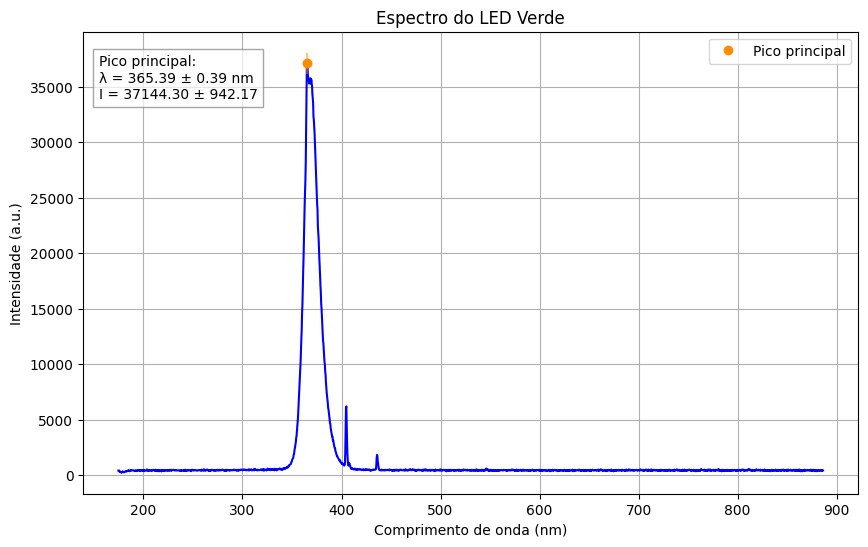

Pico principal: λ = 365.39 ± 0.39 nm, I = 37144.30 ± 942.17


In [24]:
import numpy as np
import matplotlib.pyplot as plt

# Caminho do arquivo
file_path = '/content/drive/MyDrive/F740/LUZ_NEGRA_ULTRA_VIOLETA.txt'

# Função para limpar números (remover BOM e substituir vírgula por ponto)
def clean_number(x):
    return float(x.strip().replace('\ufeff', '').replace(',', '.'))

# Ler os dados
data = np.loadtxt(file_path, converters={0: clean_number, 1: clean_number})
wavelength = data[:,0]  # nm
intensity = data[:,1]

# Encontrar o pico principal
idx_max = np.argmax(intensity)
lambda_peak = wavelength[idx_max]
intensity_peak = intensity[idx_max]

# Estimar incertezas
sigma_lambda = wavelength[1] - wavelength[0]  # ±1 pixel
sigma_intensity = np.std(intensity[max(0, idx_max-2):idx_max+3])  # ±2 pontos vizinhos

# Plotar espectro com o pico destacado
plt.figure(figsize=(10,6))
# Curva do espectro
line_curve, = plt.plot(wavelength, intensity, label='Espectro', color='blue')
# Pico principal
line_peak, = plt.plot(lambda_peak, intensity_peak, 'o', color='darkorange', label='Pico principal')
# Barra de erro
err_peak = plt.errorbar(lambda_peak, intensity_peak,
                        xerr=sigma_lambda, yerr=sigma_intensity,
                        fmt='o', color='darkorange', alpha=0.5)

# Legenda da curva no canto superior esquerdo
plt.legend(handles=[line_curve], loc='upper left')

# Legenda do pico no canto inferior direito
plt.legend(handles=[line_peak], loc='upper right')

# Texto do pico no canto superior esquerdo
plt.text(0.02, 0.95,  # coordenadas relativas (x, y) no eixo [0,1]
         f'Pico principal:\nλ = {lambda_peak:.2f} ± {sigma_lambda:.2f} nm\n'
         f'I = {intensity_peak:.2f} ± {sigma_intensity:.2f}',
         transform=plt.gca().transAxes, fontsize=10, verticalalignment='top',
         color='black', bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray'))

plt.xlabel('Comprimento de onda (nm)')
plt.ylabel('Intensidade (a.u.)')
plt.title('Espectro do LED Verde')
plt.grid(True)
plt.show()

print(f"Pico principal: λ = {lambda_peak:.2f} ± {sigma_lambda:.2f} nm, "
      f"I = {intensity_peak:.2f} ± {sigma_intensity:.2f}")


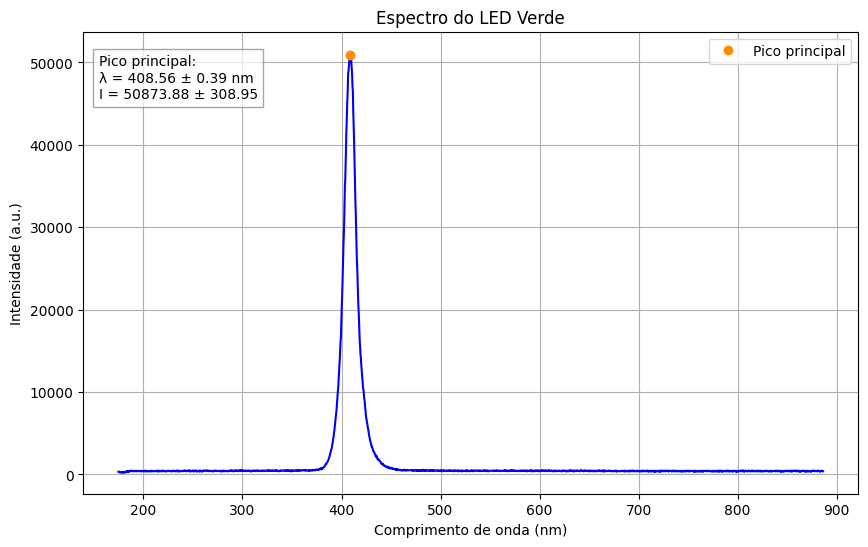

Pico principal: λ = 408.56 ± 0.39 nm, I = 50873.88 ± 308.95


In [23]:
import numpy as np
import matplotlib.pyplot as plt

# Caminho do arquivo
file_path = '/content/drive/MyDrive/F740/LED_UV_409,93.txt'

# Função para limpar números (remover BOM e substituir vírgula por ponto)
def clean_number(x):
    return float(x.strip().replace('\ufeff', '').replace(',', '.'))

# Ler os dados
data = np.loadtxt(file_path, converters={0: clean_number, 1: clean_number})
wavelength = data[:,0]  # nm
intensity = data[:,1]

# Encontrar o pico principal
idx_max = np.argmax(intensity)
lambda_peak = wavelength[idx_max]
intensity_peak = intensity[idx_max]

# Estimar incertezas
sigma_lambda = wavelength[1] - wavelength[0]  # ±1 pixel
sigma_intensity = np.std(intensity[max(0, idx_max-2):idx_max+3])  # ±2 pontos vizinhos

# Plotar espectro com o pico destacado
plt.figure(figsize=(10,6))
# Curva do espectro
line_curve, = plt.plot(wavelength, intensity, label='Espectro', color='blue')
# Pico principal
line_peak, = plt.plot(lambda_peak, intensity_peak, 'o', color='darkorange', label='Pico principal')
# Barra de erro
err_peak = plt.errorbar(lambda_peak, intensity_peak,
                        xerr=sigma_lambda, yerr=sigma_intensity,
                        fmt='o', color='darkorange', alpha=0.5)

# Legenda da curva no canto superior esquerdo
plt.legend(handles=[line_curve], loc='upper left')

# Legenda do pico no canto inferior direito
plt.legend(handles=[line_peak], loc='upper right')

# Texto do pico no canto superior esquerdo
plt.text(0.02, 0.95,  # coordenadas relativas (x, y) no eixo [0,1]
         f'Pico principal:\nλ = {lambda_peak:.2f} ± {sigma_lambda:.2f} nm\n'
         f'I = {intensity_peak:.2f} ± {sigma_intensity:.2f}',
         transform=plt.gca().transAxes, fontsize=10, verticalalignment='top',
         color='black', bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray'))

plt.xlabel('Comprimento de onda (nm)')
plt.ylabel('Intensidade (a.u.)')
plt.title('Espectro do LED Verde')
plt.grid(True)
plt.show()

print(f"Pico principal: λ = {lambda_peak:.2f} ± {sigma_lambda:.2f} nm, "
      f"I = {intensity_peak:.2f} ± {sigma_intensity:.2f}")


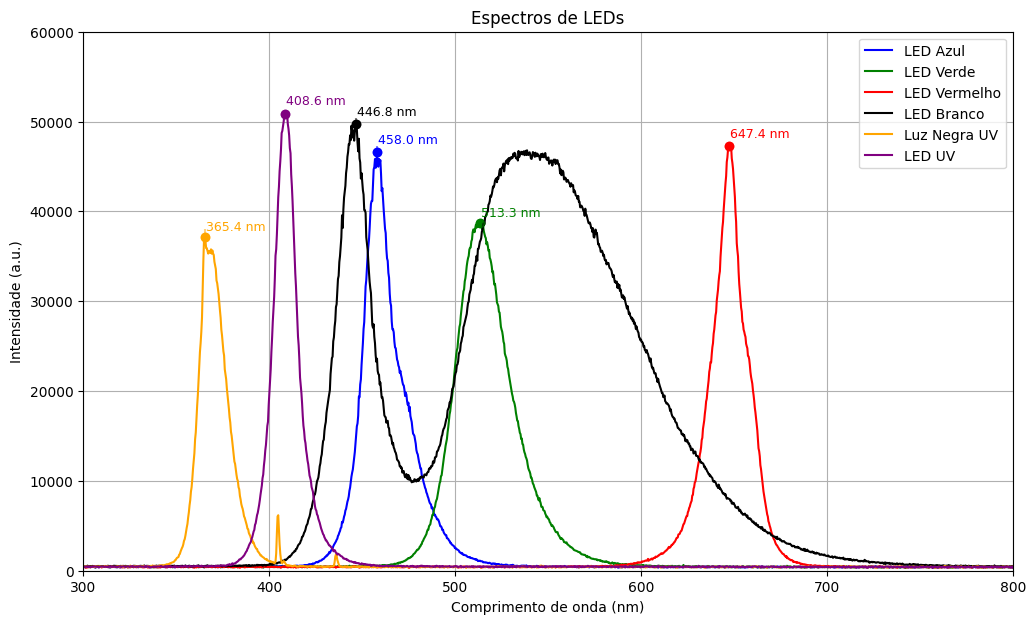

In [37]:
import numpy as np
import matplotlib.pyplot as plt

# Lista de arquivos e seus labels
files = [
    ('/content/drive/MyDrive/F740/Cópia de LED_AZUL_458,32_2.txt', 'LED Azul'),
    ('/content/drive/MyDrive/F740/LED_VERDE1_513,79.txt', 'LED Verde'),
    ('/content/drive/MyDrive/F740/LED_VERMELHO_648,78.txt', 'LED Vermelho'),
    ('/content/drive/MyDrive/F740/LED_BRANCO_454,99.txt', 'LED Branco'),
    ('/content/drive/MyDrive/F740/LUZ_NEGRA_ULTRA_VIOLETA.txt', 'Luz Negra UV'),
    ('/content/drive/MyDrive/F740/LED_UV_409,93.txt', 'LED UV')
]

# Cores para cada curva
colors = ['blue', 'green', 'red', 'black', 'orange', 'purple']

plt.figure(figsize=(12,7))

for i, (file_path, label) in enumerate(files):
    # Função para limpar números (remover BOM e substituir vírgula por ponto)
    def clean_number(x):
        return float(x.strip().replace('\ufeff', '').replace(',', '.'))

    # Ler os dados
    data = np.loadtxt(file_path, converters={0: clean_number, 1: clean_number})
    wavelength = data[:,0]  # nm
    intensity = data[:,1]

    # Encontrar pico principal
    idx_max = np.argmax(intensity)
    lambda_peak = wavelength[idx_max]
    intensity_peak = intensity[idx_max]

    # Estimar incertezas
    sigma_lambda = wavelength[1] - wavelength[0]
    sigma_intensity = np.std(intensity[max(0, idx_max-2):idx_max+3])

    # Plotar a curva
    plt.plot(wavelength, intensity, label=label, color=colors[i])

    # Marcar pico principal
    plt.plot(lambda_peak, intensity_peak, 'o', color=colors[i])
    plt.errorbar(lambda_peak, intensity_peak, xerr=sigma_lambda, yerr=sigma_intensity,
                 fmt='o', color=colors[i], alpha=0.5)

    # Adicionar texto do pico próximo ao ponto (pequeno deslocamento para não sobrepor)
    plt.text(lambda_peak+0.5, intensity_peak*1.02,
             f'{lambda_peak:.1f} nm', color=colors[i], fontsize=9)

plt.xlabel('Comprimento de onda (nm)')
plt.ylabel('Intensidade (a.u.)')
plt.xlim(300, 800)  # define eixo x entre 400 e 700 nm
plt.ylim(0, 60000)   # define eixo y entre 0 e 5000 (intensidade)
plt.title('Espectros de LEDs')
plt.legend(loc='upper right')
plt.grid(True)
plt.show()


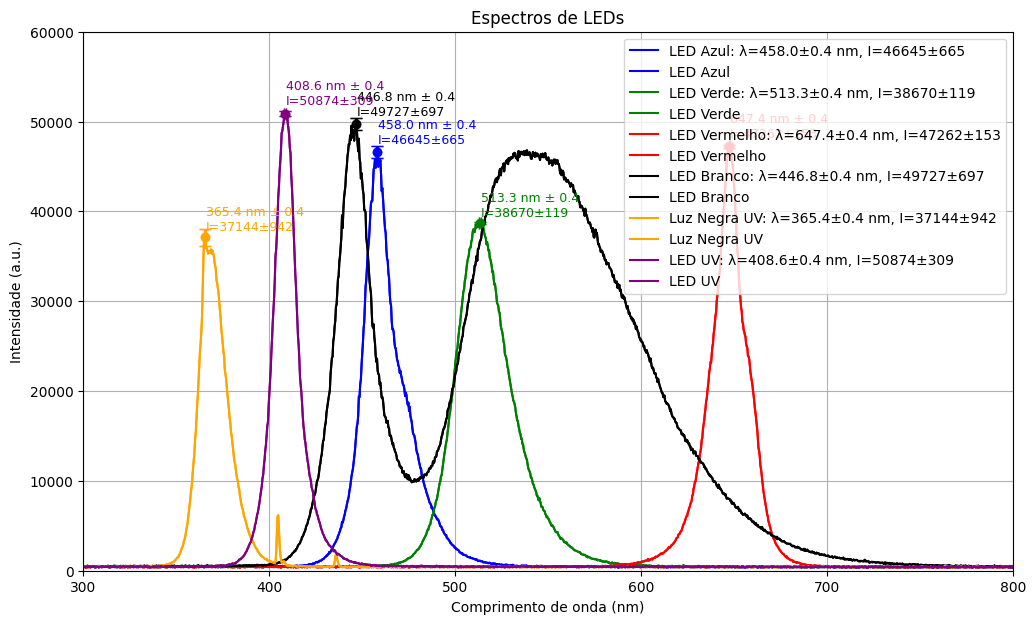

In [39]:
import numpy as np
import matplotlib.pyplot as plt

# Lista de arquivos e seus labels
files = [
    ('/content/drive/MyDrive/F740/Cópia de LED_AZUL_458,32_2.txt', 'LED Azul'),
    ('/content/drive/MyDrive/F740/LED_VERDE1_513,79.txt', 'LED Verde'),
    ('/content/drive/MyDrive/F740/LED_VERMELHO_648,78.txt', 'LED Vermelho'),
    ('/content/drive/MyDrive/F740/LED_BRANCO_454,99.txt', 'LED Branco'),
    ('/content/drive/MyDrive/F740/LUZ_NEGRA_ULTRA_VIOLETA.txt', 'Luz Negra UV'),
    ('/content/drive/MyDrive/F740/LED_UV_409,93.txt', 'LED UV')
]

# Cores para cada curva
colors = ['blue', 'green', 'red', 'black', 'orange', 'purple']

plt.figure(figsize=(12,7))

for i, (file_path, label) in enumerate(files):
    # Função para limpar números (remover BOM e substituir vírgula por ponto)
    def clean_number(x):
        return float(x.strip().replace('\ufeff', '').replace(',', '.'))

    # Ler os dados
    data = np.loadtxt(file_path, converters={0: clean_number, 1: clean_number})
    wavelength = data[:,0]  # nm
    intensity = data[:,1]

    # Encontrar pico principal
    idx_max = np.argmax(intensity)
    lambda_peak = wavelength[idx_max]
    intensity_peak = intensity[idx_max]

    # Estimar incertezas
    sigma_lambda = wavelength[1] - wavelength[0]  # ±1 pixel
    sigma_intensity = np.std(intensity[max(0, idx_max-2):idx_max+3])  # ±2 pontos vizinhos

    # Dentro do loop, depois de calcular pico e incerteza
    label_with_peak = f"{label}: λ={lambda_peak:.1f}±{sigma_lambda:.1f} nm, I={intensity_peak:.0f}±{sigma_intensity:.0f}"

# Plota a curva usando o novo label
    plt.plot(wavelength, intensity, label=label_with_peak, color=colors[i])

# Marca o pico com barra de erro (sem texto extra)
    plt.errorbar(lambda_peak, intensity_peak,
                 xerr=sigma_lambda, yerr=sigma_intensity,
                 fmt='o', color=colors[i], ecolor=colors[i], elinewidth=2, capsize=4, alpha=0.8)


    # Plotar a curva
    plt.plot(wavelength, intensity, label=label, color=colors[i])

    # Marcar pico principal com barra de erro
    plt.errorbar(lambda_peak, intensity_peak,
                 xerr=sigma_lambda, yerr=sigma_intensity,
                 fmt='o', color=colors[i], ecolor=colors[i], elinewidth=2, capsize=4, alpha=0.8)

    # Adicionar texto do pico próximo ao ponto (pequeno deslocamento)
    plt.text(lambda_peak+0.5, intensity_peak*1.02,
             f'{lambda_peak:.1f} nm ± {sigma_lambda:.1f}\nI={intensity_peak:.0f}±{sigma_intensity:.0f}',
             color=colors[i], fontsize=9)

plt.xlabel('Comprimento de onda (nm)')
plt.ylabel('Intensidade (a.u.)')
plt.xlim(300, 800)
plt.ylim(0, 60000)
plt.title('Espectros de LEDs')
plt.legend(loc='upper right')
plt.grid(True)
plt.show()


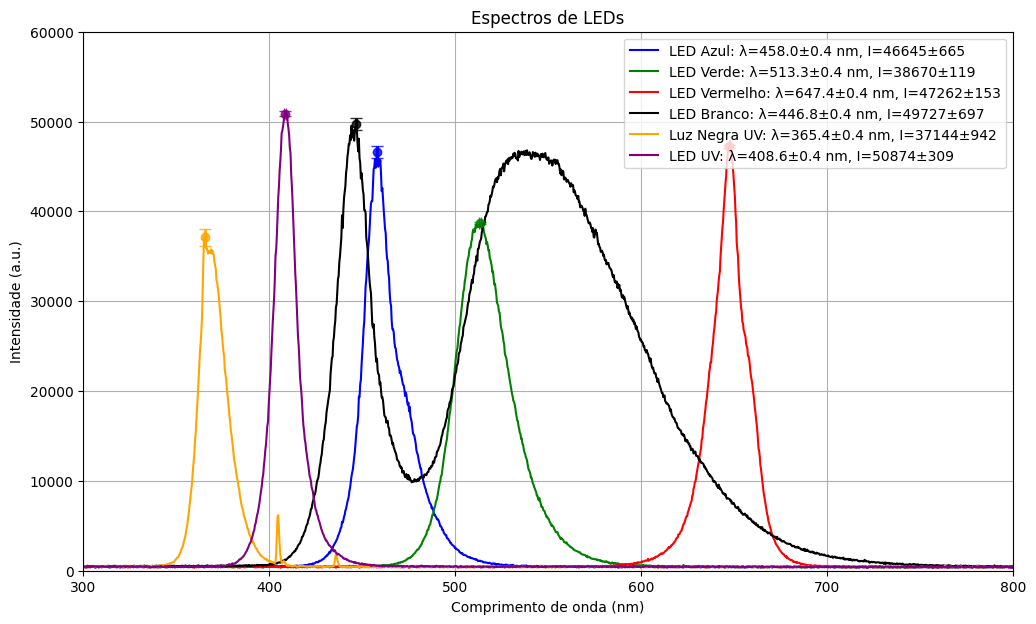

In [40]:
import numpy as np
import matplotlib.pyplot as plt

# Lista de arquivos e seus labels
files = [
    ('/content/drive/MyDrive/F740/Cópia de LED_AZUL_458,32_2.txt', 'LED Azul'),
    ('/content/drive/MyDrive/F740/LED_VERDE1_513,79.txt', 'LED Verde'),
    ('/content/drive/MyDrive/F740/LED_VERMELHO_648,78.txt', 'LED Vermelho'),
    ('/content/drive/MyDrive/F740/LED_BRANCO_454,99.txt', 'LED Branco'),
    ('/content/drive/MyDrive/F740/LUZ_NEGRA_ULTRA_VIOLETA.txt', 'Luz Negra UV'),
    ('/content/drive/MyDrive/F740/LED_UV_409,93.txt', 'LED UV')
]

# Cores para cada curva
colors = ['blue', 'green', 'red', 'black', 'orange', 'purple']

plt.figure(figsize=(12,7))

for i, (file_path, label) in enumerate(files):
    # Função para limpar números (remover BOM e substituir vírgula por ponto)
    def clean_number(x):
        return float(x.strip().replace('\ufeff', '').replace(',', '.'))

    # Ler os dados
    data = np.loadtxt(file_path, converters={0: clean_number, 1: clean_number})
    wavelength = data[:,0]  # nm
    intensity = data[:,1]

    # Encontrar pico principal
    idx_max = np.argmax(intensity)
    lambda_peak = wavelength[idx_max]
    intensity_peak = intensity[idx_max]

    # Estimar incertezas
    sigma_lambda = wavelength[1] - wavelength[0]  # ±1 pixel
    sigma_intensity = np.std(intensity[max(0, idx_max-2):idx_max+3])  # ±2 pontos vizinhos

    # Criar label incluindo os valores dos picos
    label_with_peak = f"{label}: λ={lambda_peak:.1f}±{sigma_lambda:.1f} nm, I={intensity_peak:.0f}±{sigma_intensity:.0f}"

    # Plotar curva com pico destacado e barra de erro
    plt.plot(wavelength, intensity, label=label_with_peak, color=colors[i])
    plt.errorbar(lambda_peak, intensity_peak,
                 xerr=sigma_lambda, yerr=sigma_intensity,
                 fmt='o', color=colors[i], ecolor=colors[i], elinewidth=2, capsize=4, alpha=0.8)

plt.xlabel('Comprimento de onda (nm)')
plt.ylabel('Intensidade (a.u.)')
plt.xlim(300, 800)
plt.ylim(0, 60000)
plt.title('Espectros de LEDs')
plt.legend(loc='upper right')
plt.grid(True)
plt.show()


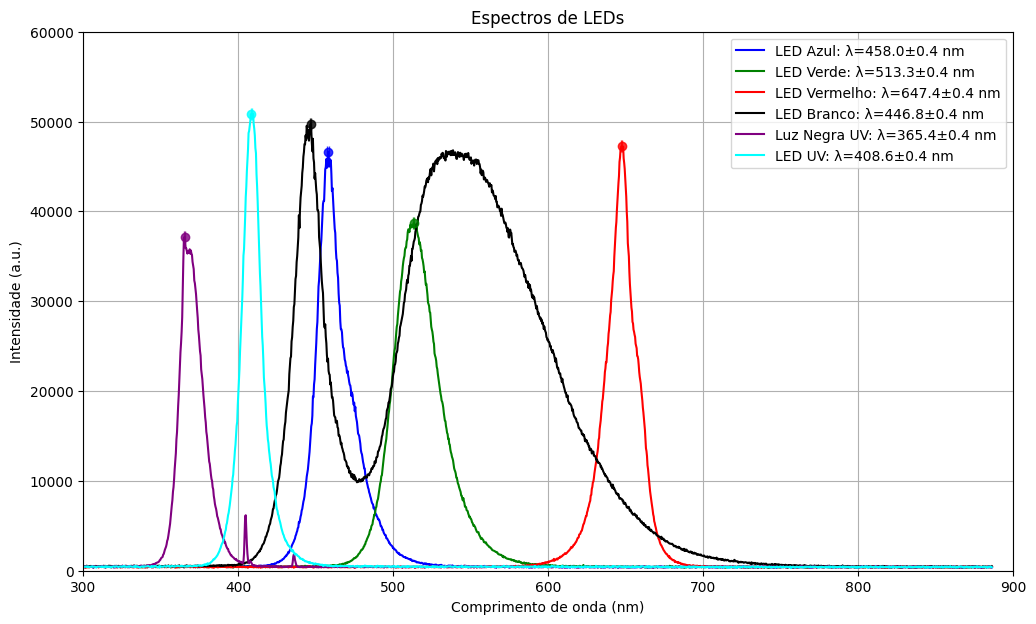

In [44]:
import numpy as np
import matplotlib.pyplot as plt

# Lista de arquivos e seus labels
files = [
    ('/content/drive/MyDrive/F740/Cópia de LED_AZUL_458,32_2.txt', 'LED Azul'),
    ('/content/drive/MyDrive/F740/LED_VERDE1_513,79.txt', 'LED Verde'),
    ('/content/drive/MyDrive/F740/LED_VERMELHO_648,78.txt', 'LED Vermelho'),
    ('/content/drive/MyDrive/F740/LED_BRANCO_454,99.txt', 'LED Branco'),
    ('/content/drive/MyDrive/F740/LUZ_NEGRA_ULTRA_VIOLETA.txt', 'Luz Negra UV'),
    ('/content/drive/MyDrive/F740/LED_UV_409,93.txt', 'LED UV')
]

# Cores para cada curva
colors = ['blue', 'green', 'red', 'black', 'purple', 'cyan']

plt.figure(figsize=(12,7))

for i, (file_path, label) in enumerate(files):
    # Função para limpar números (remover BOM e substituir vírgula por ponto)
    def clean_number(x):
        return float(x.strip().replace('\ufeff', '').replace(',', '.'))

    # Ler os dados
    data = np.loadtxt(file_path, converters={0: clean_number, 1: clean_number})
    wavelength = data[:,0]  # nm
    intensity = data[:,1]

    # Encontrar pico principal
    idx_max = np.argmax(intensity)
    lambda_peak = wavelength[idx_max]
    intensity_peak = intensity[idx_max]

    # Estimar incerteza apenas no eixo x
    sigma_lambda = wavelength[1] - wavelength[0]  # ±1 pixel

    # Criar label incluindo apenas o pico de comprimento de onda
    label_with_peak = f"{label}: λ={lambda_peak:.1f}±{sigma_lambda:.1f} nm"

    # Plotar curva com pico destacado e barra de erro apenas no eixo x
    plt.plot(wavelength, intensity, label=label_with_peak, color=colors[i])
    plt.errorbar(lambda_peak, intensity_peak,
                 xerr=sigma_lambda,
                 fmt='o', color=colors[i], ecolor=colors[i], elinewidth=2, capsize=4, alpha=0.8)

plt.xlabel('Comprimento de onda (nm)')
plt.ylabel('Intensidade (a.u.)')
plt.xlim(300, 900)
plt.ylim(0, 60000)
plt.title('Espectros de LEDs')
plt.legend(loc='upper right')
plt.grid(True)
plt.show()
